# Projekt 2: Human Activity Recognition z siecia MLP

**Cel:** klasyfikacja aktywnosci wykonywanej przez osobe noszaca smartfon na podstawie cech
z akcelerometru i zyroskopu.

Zbior UCI HAR udostepnia dla kazdego okna pomiarowego gotowy wektor `561` cech
czasowych i czestotliwosciowych oraz etykiete jednej z szesciu aktywnosci.
Dlatego pierwsza architektura sieciowa w tym notebooku to gesty perceptron
wielowarstwowy **MLP**. Surowe okna sygnalow inercyjnych sa rowniez dostepne
i moga posluzyc pozniej do wariantu `1D CNN`.

## Plan eksperymentu

1. Wczytanie pobranych plikow UCI HAR i kontrola splitu.
2. Analiza rozkladu klas, liczby osob i zakresow cech.
3. Podglad surowych okien sygnalu, z ktorych wyliczono cechy.
4. Baseline sieci MLP na dostarczonym splicie `train/test`.
5. Tuning malej architektury MLP wylacznie na train.
6. Ewaluacja najlepszego modelu na oryginalnym tescie obejmujacym inne osoby.

Dostarczony podzial zostal wykonany po wolontariuszach, dlatego nie mieszamy
wszystkich wierszy przez losowy `train_test_split`. Przy tuningu wykorzystamy
`StratifiedGroupKFold`, gdzie grupa to identyfikator osoby.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

HAR_ROOT = (
    Path("human+activity+recognition+using+smartphones")
    / "UCI HAR Dataset"
    / "UCI HAR Dataset"
)
assert HAR_ROOT.exists(), f"Nie znaleziono katalogu HAR: {HAR_ROOT.resolve()}"

print(f"Katalog danych: {HAR_ROOT.resolve()}")

Katalog danych: C:\Users\piotr\Desktop\Bartman SI\Projekt 2\human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset


## 1. Wczytanie danych

Nazwy cech z `features.txt` zawieraja znaki opisujace statystyki sygnalu.
Do kazdej nazwy dodajemy numer cechy, aby kolumny DataFrame byly jednoznaczne.

In [2]:
activity_labels = pd.read_csv(
    HAR_ROOT / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"],
)
activity_map = dict(zip(activity_labels["activity_id"], activity_labels["activity"]))

features = pd.read_csv(
    HAR_ROOT / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_index", "feature_name"],
)
feature_columns = [
    f"f{feature_index:03d}_{feature_name}"
    for feature_index, feature_name in zip(features["feature_index"], features["feature_name"])
]

def read_vector(path, column_name):
    return pd.read_csv(path, sep=r"\s+", header=None, names=[column_name])[column_name]

X_train = pd.read_csv(HAR_ROOT / "train" / "X_train.txt", sep=r"\s+", header=None, names=feature_columns)
X_test = pd.read_csv(HAR_ROOT / "test" / "X_test.txt", sep=r"\s+", header=None, names=feature_columns)
y_train = read_vector(HAR_ROOT / "train" / "y_train.txt", "activity_id").astype(int)
y_test = read_vector(HAR_ROOT / "test" / "y_test.txt", "activity_id").astype(int)
subject_train = read_vector(HAR_ROOT / "train" / "subject_train.txt", "subject_id").astype(int)
subject_test = read_vector(HAR_ROOT / "test" / "subject_test.txt", "subject_id").astype(int)

print(f"Train X: {X_train.shape}, y: {y_train.shape}")
print(f"Test  X: {X_test.shape}, y: {y_test.shape}")
print(f"Liczba cech z features.txt: {len(feature_columns)}")
print(f"Aktywnosci: {activity_map}")
X_train.iloc[:5, :8]

Train X: (7352, 561), y: (7352,)
Test  X: (2947, 561), y: (2947,)
Liczba cech z features.txt: 561
Aktywnosci: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


,f001_tBodyAcc-mean()-X,f002_tBodyAcc-mean()-Y,f003_tBodyAcc-mean()-Z,f004_tBodyAcc-std()-X,f005_tBodyAcc-std()-Y,f006_tBodyAcc-std()-Z,f007_tBodyAcc-mad()-X,f008_tBodyAcc-mad()-Y
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672


In [3]:
split_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "windows": [len(X_train), len(X_test)],
        "features": [X_train.shape[1], X_test.shape[1]],
        "subjects": [subject_train.nunique(), subject_test.nunique()],
        "missing_values": [int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum())],
        "min_feature_value": [X_train.min().min(), X_test.min().min()],
        "max_feature_value": [X_train.max().max(), X_test.max().max()],
    }
)

display(split_summary.round(4))
print(f"Osoby train: {sorted(subject_train.unique())}")
print(f"Osoby test:  {sorted(subject_test.unique())}")
print(f"Czesc wspolna osob: {sorted(set(subject_train.unique()) & set(subject_test.unique()))}")

,split,windows,features,subjects,missing_values,min_feature_value,max_feature_value
0,train,7352,561,21,0,-1.0,1.0
1,test,2947,561,9,0,-1.0,1.0


Osoby train: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Osoby test:  [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Czesc wspolna osob: []


## 2. Rozklad klas i podglad przestrzeni cech

Klasy nie sa idealnie rowne, ale kazda ma ponad kilkaset okien zarowno w train,
jak i w tescie. Dla modelu wieloklasowego raportujemy metryki per klasa oraz
`macro F1` obok accuracy.

,split,activity_id,activity,windows,share_percent
0,train,1,WALKING,1226,16.7
1,train,2,WALKING_UPSTAIRS,1073,14.6
2,train,3,WALKING_DOWNSTAIRS,986,13.4
3,train,4,SITTING,1286,17.5
4,train,5,STANDING,1374,18.7
5,train,6,LAYING,1407,19.1
6,test,1,WALKING,496,16.8
7,test,2,WALKING_UPSTAIRS,471,16.0
8,test,3,WALKING_DOWNSTAIRS,420,14.3
9,test,4,SITTING,491,16.7


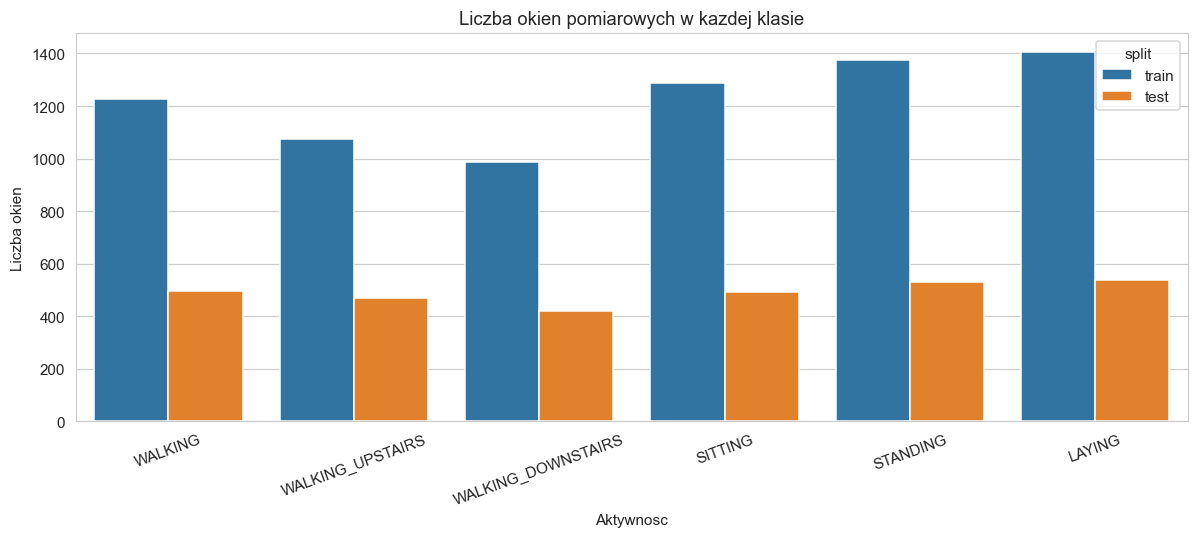

In [4]:
def class_count_table(labels, split_name):
    counts = labels.value_counts().sort_index()
    return pd.DataFrame(
        {
            "split": split_name,
            "activity_id": counts.index,
            "activity": [activity_map[class_id] for class_id in counts.index],
            "windows": counts.values,
            "share_percent": (counts.values / counts.values.sum() * 100).round(1),
        }
    )

class_counts = pd.concat(
    [class_count_table(y_train, "train"), class_count_table(y_test, "test")],
    ignore_index=True,
)
display(class_counts)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=class_counts, x="activity", y="windows", hue="split", ax=ax)
ax.set_title("Liczba okien pomiarowych w kazdej klasie")
ax.set_xlabel("Aktywnosc")
ax.set_ylabel("Liczba okien")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

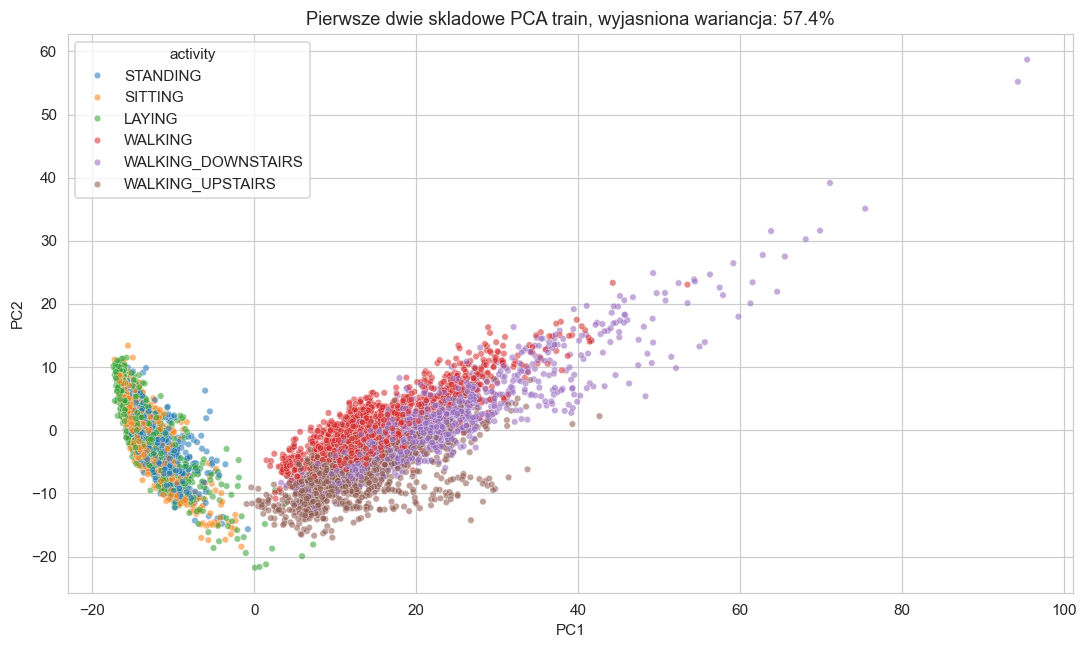

In [5]:
pca_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
    ]
)
train_pca = pca_pipeline.fit_transform(X_train)
pca_df = pd.DataFrame(
    {
        "PC1": train_pca[:, 0],
        "PC2": train_pca[:, 1],
        "activity": y_train.map(activity_map),
    }
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="activity",
    s=18,
    alpha=0.55,
    ax=ax,
)
explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_.sum()
ax.set_title(f"Pierwsze dwie skladowe PCA train, wyjasniona wariancja: {explained:.1%}")
plt.tight_layout()
plt.show()

## 3. Skad biora sie cechy HAR

Model MLP uczy sie na gotowych wektorach cech. Ponizszy wykres pokazuje jednak
przykladowe okna surowego sygnalu `body_acc_x`: kazdy wiersz ma `128` probek
pomiaru z jednego okna czasowego.

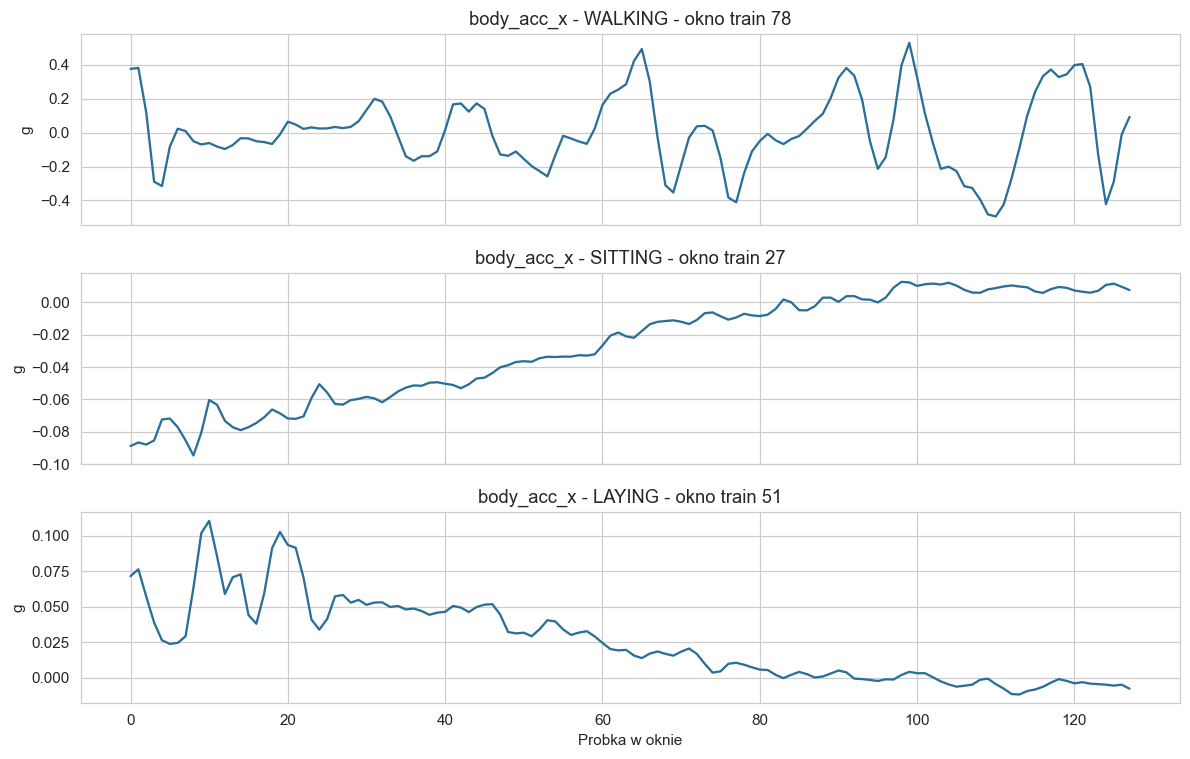

In [6]:
body_acc_x_train = pd.read_csv(
    HAR_ROOT / "train" / "Inertial Signals" / "body_acc_x_train.txt",
    sep=r"\s+",
    header=None,
)

example_class_ids = [1, 4, 6]
fig, axes = plt.subplots(len(example_class_ids), 1, figsize=(11, 7), sharex=True)

for ax, class_id in zip(axes, example_class_ids):
    row_index = y_train[y_train == class_id].index[0]
    ax.plot(body_acc_x_train.iloc[row_index].to_numpy(), color="#2a6f97")
    ax.set_title(f"body_acc_x - {activity_map[class_id]} - okno train {row_index}")
    ax.set_ylabel("g")

axes[-1].set_xlabel("Probka w oknie")
plt.tight_layout()
plt.show()

## 4. Baseline: MLP na gotowych cechach

README zbioru podaje, ze cechy sa juz ograniczone do zakresu `[-1, 1]`.
Mimo tego uzywamy `StandardScaler` w pipeline, bo MLP korzysta na porownywalnych
srednich i wariancjach cech pochodzacych z roznych statystyk sygnalu.

In [7]:
def make_mlp(hidden_layer_sizes=(128, 64), alpha=1e-4, learning_rate_init=1e-3):
    return MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        batch_size=128,
        learning_rate_init=learning_rate_init,
        max_iter=400,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE,
    )

mlp_baseline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", make_mlp()),
    ]
)
mlp_baseline.fit(X_train, y_train)
baseline_predictions = mlp_baseline.predict(X_test)

print(f"Iteracje baseline: {mlp_baseline.named_steps['model'].n_iter_}")
print(
    "Najlepszy validation score baseline: "
    f"{mlp_baseline.named_steps['model'].best_validation_score_:.4f}"
)

Iteracje baseline: 51
Najlepszy validation score baseline: 0.9819


In [8]:
def metric_row(model_name, y_true, y_pred):
    per_class_f1 = f1_score(y_true, y_pred, labels=sorted(activity_map), average=None)
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro"),
        "Recall_macro": recall_score(y_true, y_pred, average="macro"),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    row.update(
        {
            f"F1_{activity_map[class_id]}": score
            for class_id, score in zip(sorted(activity_map), per_class_f1)
        }
    )
    return row

baseline_metrics = pd.DataFrame(
    [metric_row("MLP baseline", y_test, baseline_predictions)]
).set_index("Model")

baseline_metrics.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_WALKING,F1_WALKING_UPSTAIRS,F1_WALKING_DOWNSTAIRS,F1_SITTING,F1_STANDING,F1_LAYING
Model,,,,,,,,,,
MLP baseline,0.9427,0.9458,0.9416,0.9427,0.9751,0.9498,0.9425,0.9029,0.9057,0.9801


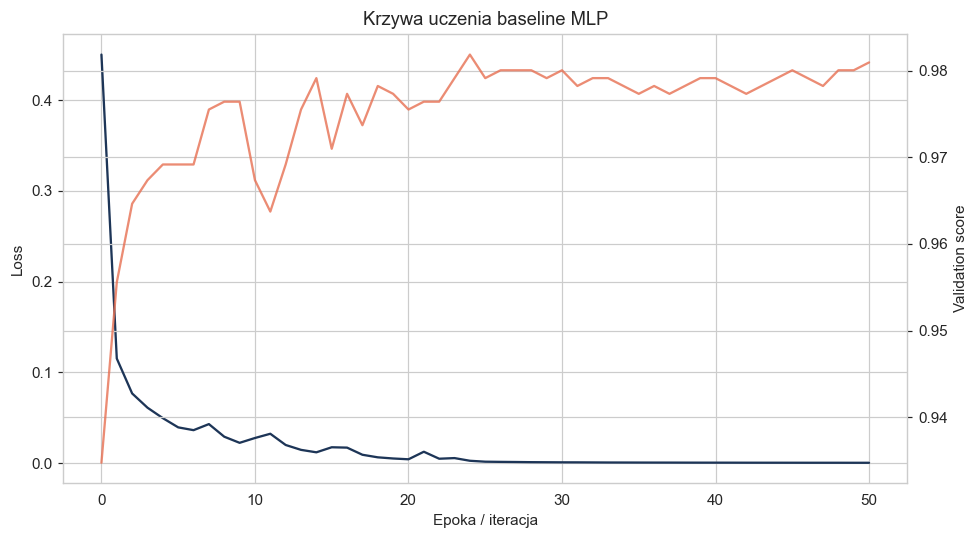

In [9]:
baseline_model = mlp_baseline.named_steps["model"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(baseline_model.loss_curve_, color="#1d3557", label="train loss")
ax.set_title("Krzywa uczenia baseline MLP")
ax.set_xlabel("Epoka / iteracja")
ax.set_ylabel("Loss")

validation_axis = ax.twinx()
validation_axis.plot(
    baseline_model.validation_scores_,
    color="#e76f51",
    alpha=0.8,
    label="validation score",
)
validation_axis.set_ylabel("Validation score")
plt.tight_layout()
plt.show()

## 5. Tuning MLP na zbiorze treningowym

Sprawdzamy kilka nieduzych architektur, regularyzacje `alpha` i poczatkowy
learning rate. Walidacja grupowa ogranicza sytuacje, w ktorej okna tej samej
osoby wystepuja jednoczesnie w foldzie treningowym i walidacyjnym.

In [10]:
group_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

tuning_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", make_mlp()),
    ]
)

param_grid = {
    "model__hidden_layer_sizes": [(64,), (128,), (128, 64), (256, 128)],
    "model__alpha": [1e-4, 1e-3],
    "model__learning_rate_init": [5e-4, 1e-3],
}

mlp_grid = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)
mlp_grid.fit(X_train, y_train, groups=subject_train)

print(f"Najlepsze parametry: {mlp_grid.best_params_}")
print(f"Najlepszy wynik group CV macro F1: {mlp_grid.best_score_:.4f}")

Fitting 4 folds for each of 16 candidates, totalling 64 fits


Najlepsze parametry: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64,), 'model__learning_rate_init': 0.001}
Najlepszy wynik group CV macro F1: 0.9285


In [11]:
cv_results = (
    pd.DataFrame(mlp_grid.cv_results_)
    .sort_values("rank_test_score")
    [
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "param_model__hidden_layer_sizes",
            "param_model__alpha",
            "param_model__learning_rate_init",
        ]
    ]
    .head(10)
)

cv_results.round(4)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_model__hidden_layer_sizes,param_model__alpha,param_model__learning_rate_init
1,1,0.9285,0.0506,0.9987,"(64,)",0.0001,0.0010
9,2,0.9284,0.0507,0.9984,"(64,)",0.0010,0.0010
0,3,0.9280,0.0459,0.9982,"(64,)",0.0001,0.0005
14,4,0.9266,0.0444,0.9988,"(256, 128)",0.0010,0.0005
6,5,0.9264,0.0442,0.9987,"(256, 128)",0.0001,0.0005
4,6,0.9262,0.0439,0.9974,"(128, 64)",0.0001,0.0005
11,7,0.9262,0.0479,0.9983,"(128,)",0.0010,0.0010
10,8,0.9254,0.0474,0.9983,"(128,)",0.0010,0.0005
12,9,0.9253,0.0421,0.9978,"(128, 64)",0.0010,0.0005
3,10,0.9252,0.0477,0.9978,"(128,)",0.0001,0.0010


## 6. Ewaluacja najlepszego MLP na oryginalnym tescie

In [12]:
best_mlp = mlp_grid.best_estimator_
best_predictions = best_mlp.predict(X_test)

comparison = pd.DataFrame(
    [
        metric_row("MLP baseline", y_test, baseline_predictions),
        metric_row("MLP tuned", y_test, best_predictions),
    ]
).set_index("Model")

comparison.round(4).sort_values("F1_macro", ascending=False)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_WALKING,F1_WALKING_UPSTAIRS,F1_WALKING_DOWNSTAIRS,F1_SITTING,F1_STANDING,F1_LAYING
Model,,,,,,,,,,
MLP tuned,0.9433,0.9492,0.9418,0.9434,0.9743,0.9478,0.9492,0.8991,0.9077,0.9820
MLP baseline,0.9427,0.9458,0.9416,0.9427,0.9751,0.9498,0.9425,0.9029,0.9057,0.9801


Classification report - najlepszy MLP
                    precision    recall  f1-score   support

           WALKING       0.96      0.99      0.97       496
  WALKING_UPSTAIRS       0.93      0.96      0.95       471
WALKING_DOWNSTAIRS       0.99      0.91      0.95       420
           SITTING       0.97      0.84      0.90       491
          STANDING       0.85      0.98      0.91       532
            LAYING       1.00      0.97      0.98       537

          accuracy                           0.94      2947
         macro avg       0.95      0.94      0.94      2947
      weighted avg       0.95      0.94      0.94      2947



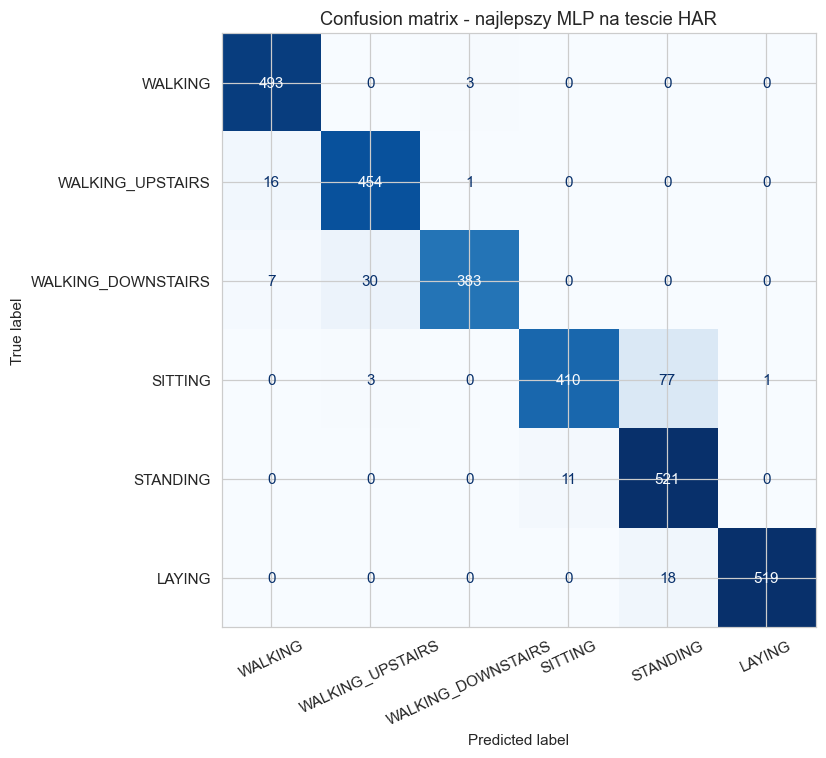

In [13]:
target_names = [activity_map[class_id] for class_id in sorted(activity_map)]
print("Classification report - najlepszy MLP")
print(classification_report(y_test, best_predictions, target_names=target_names))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=sorted(activity_map),
    display_labels=target_names,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=25,
    ax=ax,
)
ax.set_title("Confusion matrix - najlepszy MLP na tescie HAR")
plt.tight_layout()
plt.show()

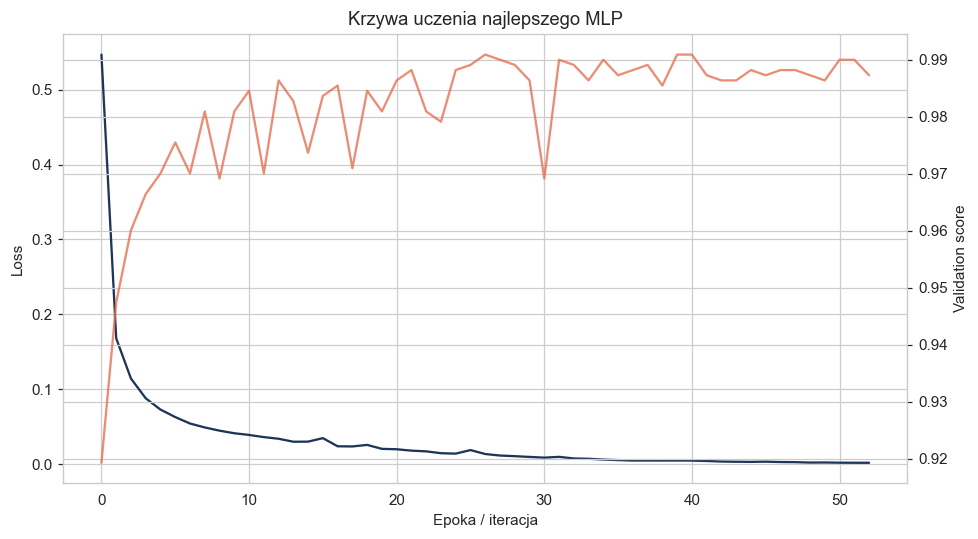

Iteracje najlepszego MLP: 53
Najlepszy validation score early stopping: 0.9909


In [14]:
best_model = best_mlp.named_steps["model"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(best_model.loss_curve_, color="#1d3557", label="train loss")
ax.set_title("Krzywa uczenia najlepszego MLP")
ax.set_xlabel("Epoka / iteracja")
ax.set_ylabel("Loss")

validation_axis = ax.twinx()
validation_axis.plot(
    best_model.validation_scores_,
    color="#e76f51",
    alpha=0.8,
    label="validation score",
)
validation_axis.set_ylabel("Validation score")
plt.tight_layout()
plt.show()

print(f"Iteracje najlepszego MLP: {best_model.n_iter_}")
print(f"Najlepszy validation score early stopping: {best_model.best_validation_score_:.4f}")

## 7. Wnioski

Zbior UCI HAR okazal sie dobrym materialem do projektu z siecia MLP. Dostarczone
pliki zawieraja `7352` okna treningowe i `2947` okien testowych opisanych przez
`561` cech. Klasy sa znacznie rowniejsze niz w poprzednim zbiorze fetal health,
nie wystepuja braki danych, a oryginalny split rozdziela osoby treningowe i
testowe. W tym eksperymencie zachowano ten podzial, dlatego wynik testowy mierzy
uogolnianie modelu na innych wolontariuszy, a nie tylko na inne okna tej samej osoby.

### Wyniki MLP

Juz baseline MLP z dwiema warstwami ukrytymi `(128, 64)` uzyskal na oryginalnym
tescie `accuracy = 0.9427` oraz `macro F1 = 0.9427`. Tuning grupowy po
identyfikatorze osoby wskazal prostsza architekture z jedna warstwa `(64,)`,
`alpha = 0.0001` i `learning_rate_init = 0.001`. Jej sredni wynik w
`StratifiedGroupKFold` wyniosl `macro F1 = 0.9285`, a na odlozonym tescie
dostrojony model osiagnal `accuracy = 0.9433` i `macro F1 = 0.9434`.

Roznica miedzy baseline i modelem dostrojonym jest niewielka. Pokazuje to, ze
na gotowych cechach HAR mala siec MLP juz dobrze wykorzystuje informacje z
akcelerometru i zyroskopu, a zwiekszanie architektury nie daje automatycznie
duzego zysku. Jednoczesnie wyniki tuningu maja bardzo wysokie wyniki treningowe
i nizsze wyniki walidacji grupowej, co przypomina, ze uogolnianie miedzy osobami
jest trudniejsze niz dopasowanie okien znanych osob.

### Jakosc klasyfikacji

Najlepszy MLP bardzo dobrze rozpoznawal aktywnosci dynamiczne oraz `LAYING`:
`F1` wynioslo okolo `0.97` dla `WALKING`, `0.95` dla obu wariantow chodzenia
po schodach i `0.98` dla `LAYING`. Najtrudniejsze pozostaly klasy statyczne
`SITTING` i `STANDING`, dla ktorych uzyskano odpowiednio `F1 = 0.90` oraz
`F1 = 0.91`. Raport klasyfikacji wskazuje zwlaszcza nizszy recall klasy
`SITTING` (`0.84`), co jest zgodne z podobienstwem tych aktywnosci w danych
czujnikowych.

Wynik potwierdza, ze HAR jest lepszym zbiorem do obecnego projektu MLP niz
fetal health: ma wiecej obserwacji, wiecej cech sensorycznych i daje bardzo
wyrazny efekt klasyfikacji wieloklasowej. Naturalnym rozszerzeniem projektu
byloby pozniej porownanie tego MLP z modelem `1D CNN` uczonym na surowych oknach
sygnalow inercyjnych dostepnych w tym samym zbiorze.